# Тестовое задание

## Введение

Основной продукт твоей компании - выдача PDL займов (краткосрочный период, под ежедневный процент, до 30000). После закрытия займа клиент может взять новый, одновременно у клиента не может быть более одного займа. Один из способов привлечения новых клиентов - это размещение информации о себе на "витринах". В рамках тестового задания нужно будет рассмотреть эффективность такого привлечения для различных витрин и позиций на этих витринах, сделать выводы и дать рекомендации

## Описание процесса

Витрины - сторонние источники, на которых указан список компаний с ссылкой на их сайт и краткой информацией о них  

Ежедневно на витрине обновляется позиция компании в списке. Как правило, позиция зависит от "среднего чека" за прошлый день (или другой период) - сколько компания в среднем платит за переход по ссылке (для упрощения будем считать в среднем за выданный займ). Чем выше компания в списке, тем больше и лучше поток клиентов от этой витрины

## Данные

Находятся в папке data

`data.csv` - данные о клиентах, пришедших с витрин, признаки:
- `CLIENT` - id клиента
- `SAVE_STAMP` - дата и время оформления первого займа
- `SOURCE` - с какой витрины пришел
- `COST` - сколько заплатили витрине за привлечение, зависит от `MARK_SCORE`. Признак, от которого зависит позиция на витрине (средний чек)
- `LOAN_AMOUNT` - сумма выданного первого (!) займа
- `LOAN_AMOUNT_START` - изначально запрошенная сумма клиентом для первого (!) займа
- `MARK_SCORE` - маркетинговый скоринг, предсказывает `LTV` клиента. Чем выше скор-балл, тем прибыльнее клиент - это предсказание, т.к. скорится моделью до получения фактических значений `LTV`
- `LTV180` - полученная прибыль от клиента за 180 дней (платежи в пользу компании - сумма `LOAN_AMOUNT` всех оформленных займов за период). Не учитывает стоимость привлечения `COST`
- `LTV` - полученная прибыль от клиента за весь период с `SAVE_STAMP` до даты выгрузки (платежи - `LOAN_AMOUNT` всех оформленных займов за период). Не учитывает стоимость привлечения `COST`

`ranking.csv` - информация о позициях на витринах с частотой в 1 день, признаки:
- `SAVE_STAMP` - дата получения данных о занимаемой позиции на витрине
- `RANK` - позиция компании на витрине в указанный день
- `SOURCE` - витрина

## Задание

**Во втором пункте выбор подхода для решения задачи зависит от вакансии, на которую откликнулся кандидат: DS, DA**

Сегодня - 2 августа 2023 года (считать датой выгрузки), тебе предоставили данные для оценки трех витрин, период [01.08.22 - 01.08.23):
- Информацию о клиентах, краткой информации о их первых займах, выплатах за привлечение и `LTV` клиента на разных периодах `data.csv`
- Информацию о занимаемой позиции в указанный день на витрине `ranking.csv`

1. Провести исследовательский анализ на первом полугодии выгрузки [01.08.22 - 01.02.23):
   - Изучить изменения `LTV`, `LTV180`, `MARK_SCORE`, `LOAN_AMOUNT` в зависимости от витрины, занимаемого места
   - Определить средний чек `COST` для места внутри витрины на этом периоде
   - Проверить, влияет ли период (например, месяц) выгрузки на занимаемое место и средний чек
   - Учесть затраты на маркетинг, сделать выводы об окупаемости клиентов на всем периоде `LTV` (для каждого клиента разный период, начиная с `SAVE_SATMP`) и `LTV180` (для всех зафиксирован период 180 дней с `SAVE_STAMP`) внутри витрины/места
   - Сделать вывод связи `MARK_SCORE` с `LTV` у клиента в разрезе витрин/мест, общая взаимосвязь без группировки
2. На втором полугодии [01.02.23 - 01.08.23) разработать (**DA**): [формулу, рекомендации на основе анализа], (**DS**): [алгоритм/формулу/модель], которая будет оценивать насколько поток за рассматриваемый день соответствует витрине/месту. Пример: Определить на 23.06.23 соответствовал ли ожидаемому поток на source_1 зафиксированному в этот день месту, сделать выводы о целесообразности изменения места:
    - Стоит использовать свежий период, например на 7 дней назад (на примере 23.06 [16.06 - 22.06]) или другой период
    - Используй признак `MARK_SCORE` и кол-во клиентов как определитель качества потока. `LTV` - это метрика, которая отражает фактическую прибыльность клиента и вызревает долгое время (`LTV180` вызревает 180 дней), поэтому её нельзя использовать для быстрой оценки качества потока. Для этого есть `MARK_SCORE`, который предсказывает прибыльность клиента
    -  Определённая взаимосвязь `LTV` и `MARK_SCORE` в первой части задания помогут сформировать признаки/метрики, определяющие качество потока, однако сравнивать поток клиентов лучше с недавним потоком с той же витриной и местом по `MARK_SCORE` и кол-ву клиентов
    -  Не забудь учесть расходы на маркетинг `COST`
    -  Дать оценку на 01.08.23, дать оценку текущему потоку, рекомендации по изменению места. Вне зависимости от выбранного метода, объяснить решение и принцип работы подхода
    -  Если оценка невозможна, написать причины, каких данных не хватает для оценки

Задание можно выполнять в этой тетрадке, должно быть выполнено в Jupyter или GoogleColab в формате .ipynb без внешних файлов

Удачи!

# Решение

In [1536]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from phik import phik_matrix
from scipy import stats
import dateutil.relativedelta as rd

## 0. Загрузка данных 

### Датасет `data`

In [1537]:
# загружаем датасет data в датафрейм
df_data_raw = pd.read_csv('data/data.csv')

In [1538]:
# выведем первые строки датафрейма. 
df_data_raw.head()

,CLIENT,SAVE_STAMP,SOURCE,COST,LOAN_AMOUNT,LOAN_AMOUNT_START,MARK_SCORE,LTV180,LTV
0,47204859,2022-08-01 00:03:12,source_1,5500.0,9000.0,9000.0,0.879,8062.67250,20504.98154
1,47204418,2022-08-01 00:05:21,source_1,4200.0,14000.0,30000.0,0.554,-18117.90400,-18117.90400
2,47204910,2022-08-01 00:12:54,source_2,4200.0,6000.0,20000.0,0.484,5881.27737,5881.27737
3,47204974,2022-08-01 00:13:47,source_1,4200.0,6000.0,10000.0,0.628,2348.33755,18898.95905
4,47204963,2022-08-01 00:13:51,source_1,5500.0,3000.0,3000.0,0.648,4052.93700,1529.97550


In [1539]:
# выведем общую информацию
df_data_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 186371 entries, 0 to 186370
Data columns (total 9 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   CLIENT             186371 non-null  int64  
 1   SAVE_STAMP         186371 non-null  object 
 2   SOURCE             186371 non-null  object 
 3   COST               172720 non-null  float64
 4   LOAN_AMOUNT        186371 non-null  float64
 5   LOAN_AMOUNT_START  186371 non-null  float64
 6   MARK_SCORE         173744 non-null  float64
 7   LTV180             87680 non-null   float64
 8   LTV                87680 non-null   float64
dtypes: float64(6), int64(1), object(2)
memory usage: 12.8+ MB


Видим, что по полям COST, MARK_SCORE, LTV180 и LTV имеются пропуски.

In [1540]:
# поле SAVE_STAMP содержащее временную метку приведем к типу datetime 
# и для будущих группировок по дате создадим поле SAVE_STAMP_DATE без времени, 
# а также добавим поля с неделей и месяцем для возможных группировок
df_data_raw['SAVE_STAMP'] = pd.to_datetime(df_data_raw['SAVE_STAMP'])
df_data_raw['SAVE_STAMP_DATE'] = pd.to_datetime(df_data_raw['SAVE_STAMP'].dt.date)
# добавляем поле с неделей и месяцем
df_data_raw['SAVE_STAMP_WEEK'] = df_data_raw['SAVE_STAMP_DATE'].dt.to_period('W').dt.start_time
df_data_raw['SAVE_STAMP_MON'] = df_data_raw['SAVE_STAMP_DATE'].dt.to_period('M').dt.start_time

In [1541]:
# подсчитаем количество уникальных клиентов
print(f"Всего клиентов {df_data_raw['CLIENT'].count()} из них уникальных {df_data_raw['CLIENT'].nunique()}")

Всего клиентов 186371 из них уникальных 186320


Видим, что уникальных клиентов меньше, чем строк в датафрейме. Это значит, что есть записи, где ИД клиента повторяется, но есть примечание, что у клиента может быть только один действующий займ, а значит, что в таблице должно быть по одной записит на клиента. Стало быть, могут иметь место дубликаты.

In [1542]:
# проверим на полные дубликаты
print(f'Найден {df_data_raw.duplicated().sum()} полный дубликат')

Найден 51 полный дубликат


Найдены полные дубликаты. Посмотрим на них.

In [1543]:
df_data_raw[df_data_raw.duplicated()]

,CLIENT,SAVE_STAMP,SOURCE,COST,LOAN_AMOUNT,LOAN_AMOUNT_START,MARK_SCORE,LTV180,LTV,SAVE_STAMP_DATE,SAVE_STAMP_WEEK,SAVE_STAMP_MON
6397,47443827,2022-08-08 11:49:14,source_2,5500.0,26000.0,26000.0,0.678,-17528.8435,-17528.8435,2022-08-08,2022-08-08,2022-08-01
6398,47443827,2022-08-08 11:49:14,source_2,5500.0,26000.0,26000.0,0.678,-17528.8435,-17528.8435,2022-08-08,2022-08-08,2022-08-01
6399,47443827,2022-08-08 11:49:14,source_2,5500.0,26000.0,26000.0,0.678,-17528.8435,-17528.8435,2022-08-08,2022-08-08,2022-08-01
6400,47443827,2022-08-08 11:49:14,source_2,5500.0,26000.0,26000.0,0.678,-17528.8435,-17528.8435,2022-08-08,2022-08-08,2022-08-01
6401,47443827,2022-08-08 11:49:14,source_2,5500.0,26000.0,26000.0,0.678,-17528.8435,-17528.8435,2022-08-08,2022-08-08,2022-08-01
6402,47443827,2022-08-08 11:49:14,source_2,5500.0,26000.0,26000.0,0.678,-17528.8435,-17528.8435,2022-08-08,2022-08-08,2022-08-01
6403,47443827,2022-08-08 11:49:14,source_2,5500.0,26000.0,26000.0,0.678,-17528.8435,-17528.8435,2022-08-08,2022-08-08,2022-08-01
6404,47443827,2022-08-08 11:49:14,source_2,5500.0,26000.0,26000.0,0.678,-17528.8435,-17528.8435,2022-08-08,2022-08-08,2022-08-01
6405,47443827,2022-08-08 11:49:14,source_2,5500.0,26000.0,26000.0,0.678,-17528.8435,-17528.8435,2022-08-08,2022-08-08,2022-08-01
6406,47443827,2022-08-08 11:49:14,source_2,5500.0,26000.0,26000.0,0.678,-17528.8435,-17528.8435,2022-08-08,2022-08-08,2022-08-01


Обнаружено несколько клиентов, по которым записи дублируются.

In [1544]:
# удалим полные дубликаты
df_data_raw.drop_duplicates(inplace=True)

**На этом завершим первоначальную подготовку датафрейма с данными о клиентах**

### Датасет `ranking`

In [1545]:
df_rank_raw = pd.read_csv('data/ranking.csv')

In [1546]:
df_rank_raw.head()

,SAVE_STAMP,RANK,SOURCE
0,2022-08-01,1,source_1
1,2022-08-01,1,source_2
2,2022-08-01,1,source_3
3,2022-08-02,3,source_3
4,2022-08-02,1,source_2


In [1547]:
df_rank_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1033 entries, 0 to 1032
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   SAVE_STAMP  1033 non-null   object
 1   RANK        1033 non-null   int64 
 2   SOURCE      1033 non-null   object
dtypes: int64(1), object(2)
memory usage: 24.3+ KB


Пропусков в данных нет.

In [1548]:
df_rank_raw['SAVE_STAMP'] = pd.to_datetime(df_rank_raw['SAVE_STAMP'])

In [1549]:
# проверим на полные дубликаты
print(f'В датафрейме df_rank_raw обнаружено {df_rank_raw.duplicated().sum()} полных дубликатов')

В датафрейме df_rank_raw обнаружено 39 полных дубликатов


In [1550]:
# удалим полные дубликаты
df_rank_raw.drop_duplicates(inplace=True)

**На этом завершим первоначальную подготовку датафрейма с данными о позициях на витринах, объединими два датафрема в один**

In [1551]:
# объединим два датафрейма для дальнейшей работы
df = pd.merge(df_data_raw,df_rank_raw, 
                       how='left', 
                       left_on=['SAVE_STAMP_DATE','SOURCE'], right_on=['SAVE_STAMP','SOURCE']
                      )

In [1552]:
# удалим дублирующийся столбец с датой
try:
    df = df.drop(columns=['SAVE_STAMP_y'])
    df = df.rename(columns={'SAVE_STAMP_x': 'SAVE_STAMP'})
except Exception as e:
    print(f'Все уже удалили. {e}')

In [1553]:
# проверим результат объединения и удаления
df.head()

,CLIENT,SAVE_STAMP,SOURCE,COST,LOAN_AMOUNT,LOAN_AMOUNT_START,MARK_SCORE,LTV180,LTV,SAVE_STAMP_DATE,SAVE_STAMP_WEEK,SAVE_STAMP_MON,RANK
0,47204859,2022-08-01 00:03:12,source_1,5500.0,9000.0,9000.0,0.879,8062.67250,20504.98154,2022-08-01,2022-08-01,2022-08-01,1.0
1,47204418,2022-08-01 00:05:21,source_1,4200.0,14000.0,30000.0,0.554,-18117.90400,-18117.90400,2022-08-01,2022-08-01,2022-08-01,1.0
2,47204910,2022-08-01 00:12:54,source_2,4200.0,6000.0,20000.0,0.484,5881.27737,5881.27737,2022-08-01,2022-08-01,2022-08-01,1.0
3,47204974,2022-08-01 00:13:47,source_1,4200.0,6000.0,10000.0,0.628,2348.33755,18898.95905,2022-08-01,2022-08-01,2022-08-01,1.0
4,47204963,2022-08-01 00:13:51,source_1,5500.0,3000.0,3000.0,0.648,4052.93700,1529.97550,2022-08-01,2022-08-01,2022-08-01,1.0


### EDA на рабочем датафрейме

In [1554]:
# проверим диапазон дат, чтобы убедиться, что предоставлненные данные охватывают период времени, указанный в ТЗ
print(f"Минимальная дата: {df['SAVE_STAMP'].min()}")
print(f"Максимальная дата: {df['SAVE_STAMP'].max()}")

Минимальная дата: 2022-08-01 00:03:12
Максимальная дата: 2023-07-31 23:42:56


Диапазоны дат охватывают период указанный в ТЗ

In [1555]:
# проверим список витрин и частоту размещения на них
print(f"Уникальные источники {df['SOURCE'].unique()}")
df['SOURCE'].value_counts()

Уникальные источники ['source_1' 'source_2' 'source_3']


SOURCE
source_1    138430
source_3     34739
source_2     18089
Name: count, dtype: int64

Источника всего три. Необычных названий не выявлено. чаще всего размещение происходит на витрине source_1    

In [1556]:
# выведем описательную статистику по числовым полям
df.select_dtypes(include=['float64']).describe()

,COST,LOAN_AMOUNT,LOAN_AMOUNT_START,MARK_SCORE,LTV180,LTV,RANK
count,177129.000000,191258.000000,191258.000000,178377.000000,87880.000000,87880.000000,148977.000000
mean,3454.797351,8639.900030,13743.106171,0.541778,979.206716,4060.786281,2.134309
std,1132.872681,6426.207014,9493.624729,0.157615,10881.773771,14818.470539,1.670680
min,450.000000,3000.000000,3000.000000,0.047000,-65500.000000,-36554.636000,1.000000
25%,2600.000000,3000.000000,5000.000000,0.424000,-5000.000000,-4160.562500,1.000000
50%,2600.000000,6000.000000,10000.000000,0.547000,0.000000,1034.805500,1.000000
75%,4200.000000,12000.000000,20000.000000,0.659000,5750.575875,9046.050125,3.000000
max,5500.000000,30000.000000,30000.000000,0.960000,267051.629800,292135.629800,17.000000


Аномалий в COST нет, чрезмерно больших сумм нет, отрицательных тоже нет.   

Аномалий в запрошенных и выданныз суммах не наблюдается. Нет сумм больше 30000 руб. Нет отрицательных сумм.   

MARK_SCORE колеблетс в диапазоне от 0,047 до 0,96. Отрицательных значений или значений больше 1 нет.  

LTV180 и LTV имеют отрицательные значения, что вполне допустимо для случаев невозврата. Есть вопрос к величине отирцательной суммы. Если допустить, что был взят займ на 30000 руб., и не возвращен, то LTV или LTV180 должен составлять -30000 руб. Возможна ли ситуация, когда был взять второй займ при непогашенном первом? Даже если исходить из того, что `LTV(180) - это платежи (в пользу компании) - сумма LOAN_AMOUNT всех оформленных займов за период`, то остается вопрос, как может быть это значение -65500 или -36554. Это означает, что у клиента больше одного невозвращенного займа. **Считаю, что такое маловероятно, так как наращивать убытки не в интересах бизнеса**.  

Место на витрине не имеет отрицательных значений, и колеблется в диапазоне от 1 до 17. 17 реально существующий ранг, если судить по витринам МФО: https://startonlinerf.ru/, https://xn--d1ahncgkz5g.xn--p1ai/catalog/
Также видно, что в значениях есть пропуски. Оценим их количество.

In [1557]:
print(f'Всего строк в датафрейме {len(df)}')
abs_value = df.select_dtypes(include=['float64']).isna().sum()
rel_value = df.select_dtypes(include=['float64']).isna().sum()/len(df)*100

result = pd.DataFrame({
    'column': abs_value.index,
    'abs_value': abs_value.values,
    'rel_value': rel_value.values,
})
result


Всего строк в датафрейме 191258


,column,abs_value,rel_value
0,COST,14129,7.387403
1,LOAN_AMOUNT,0,0.000000
2,LOAN_AMOUNT_START,0,0.000000
3,MARK_SCORE,12881,6.734882
4,LTV180,103378,54.051595
5,LTV,103378,54.051595
6,RANK,42281,22.106788


Более 50% пропусков в полях LTV и LTV180. Также более 20% пропусков в поле RANK. Более 7% пропусков в COST.  
Пропусков много, но поля с суммами выданных займов пропусков не имеют. Едва ли займ будет выдан, если у клиента нет MARK_SCORE. Едва ли клиент сможет взять займ, если предложение не размещено на витрине (COST - NaN). Также у сервиса не будет места на витрине, когда COST - NaN.

In [1558]:
# проверим сколько записей имеется с NaN во всех перечисленных выше полях.
print(f"Записей с NaN: {len(df[(df['COST'].isna()) & (df['MARK_SCORE'].isna()) & (df['LTV180'].isna()) & (df['LTV'].isna()) & (df['RANK'].isna())])}")

Записей с NaN: 202


202 записи, у которых NaN в есть одновременно в полях COST, MARK_SCORE, LTV180, LTV, RANK.  
Эти записи можно было бы удалить, так как едва ли  получится заполнить пропуски в них.    
Что касается остальных пропусков.  
**COST**:  
1. дополнить по возможности недостающие данные из  системы, которая учитывает работу с витринами, и где хранятся транзакции по проведению оплат витринам.
2. по согласованию с Тимлидом / Продактом заполнить пропуски медианным значением по каждой площадке.

**MARK_SCORE**: Чисто теоретически можно пытаться по известному LTV вывести MARK_SCORE, так как изначально именно MARK_SCORE, полученной моделью, предсказывает LTV

**LTV**: Можно попытаться предсказать на основании известного значения MARK_SCORE  

**LTV180**: Не вижу возможностей для заполнения этого поля. Недостаточно информации. 


Также считаю, что случаи, когда LTV или LTV180 меньше -30000 являются странной ситуацией. Подсчитаем, сколько таких вхождений в данных.

In [1559]:
print(f"LTV меньше -30000: {len(df[df['LTV']<-30000])}")
print(f"LTV180 меньше -30000: {len(df[df['LTV180']<-30000])}")
print(f"LTV и LTV180 меньше -30000: {len(df[(df['LTV180']<-30000) & (df['LTV']<-30000)])}")

LTV меньше -30000: 6
LTV180 меньше -30000: 25
LTV и LTV180 меньше -30000: 5


Записей с большим отрицательным LTV немного. Пусть пока остаются.

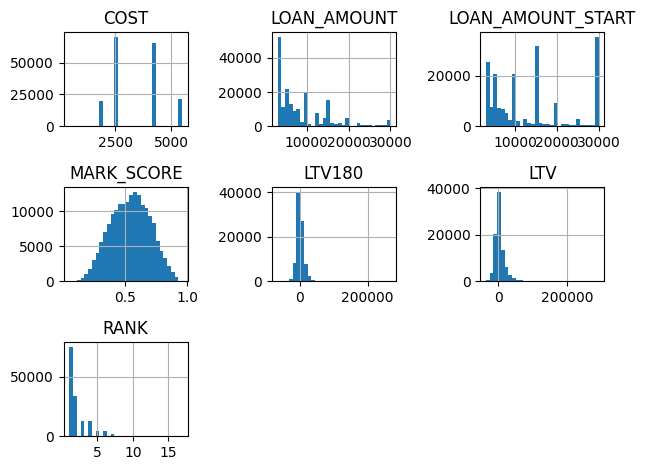

In [1560]:
# посмотрим на распределения числовых показателей
df.select_dtypes(include=['float64']).hist(bins = 30)
plt.tight_layout()
plt.show()

ОЖидаемо суммы займов имеют логнормальное распределение. Расппределения LTV, похожи на нормальные, но скошены вправо. Скор-оценка имеет распределение близкое к нормальному. Места в основной своей массе находятся в диапазоне 1-3.

#### Вывод:   

1. загружены данные из датасетов
2. приведены поля с датами к формату datetime
3. произведен поиск аномалий, дубликатов, пропусков
4. аномалий не обнаружено (за исключением больших отрицательных сумм в LTV и LTV180)
5. полные дубликаты удалены


## 1. Исследовательский анализ на первом полугодии

In [1561]:
# формируем датафрейм с данными первого полугодия
df_1 = df[df['SAVE_STAMP_DATE'].between('2022-08-01','2023-02-01')].copy()

### Изучить изменения LTV, LTV180, MARK_SCORE, LOAN_AMOUNT в зависимости от витрины, занимаемого места

Поскольку речь идет о том, чтобы изучить изменения в зависимости от витрины, занимаемого места, то правильным будет рассчитать среднее значение требуемых показателей.

In [1562]:
# создаем дф для визуализации по источникам
df_plot_src = df_1.groupby('SOURCE').agg(
    avg_ltv=('LTV','mean'),
    avg_ltv_180=('LTV180','mean'),
    avg_mark=('MARK_SCORE','mean'),
    avg_loan=('LOAN_AMOUNT','mean'),
    med_ltv=('LTV','median'),
    med_ltv_180=('LTV180','median'),
    med_mark=('MARK_SCORE','median'),
    med_loan=('LOAN_AMOUNT','median')
).reset_index()

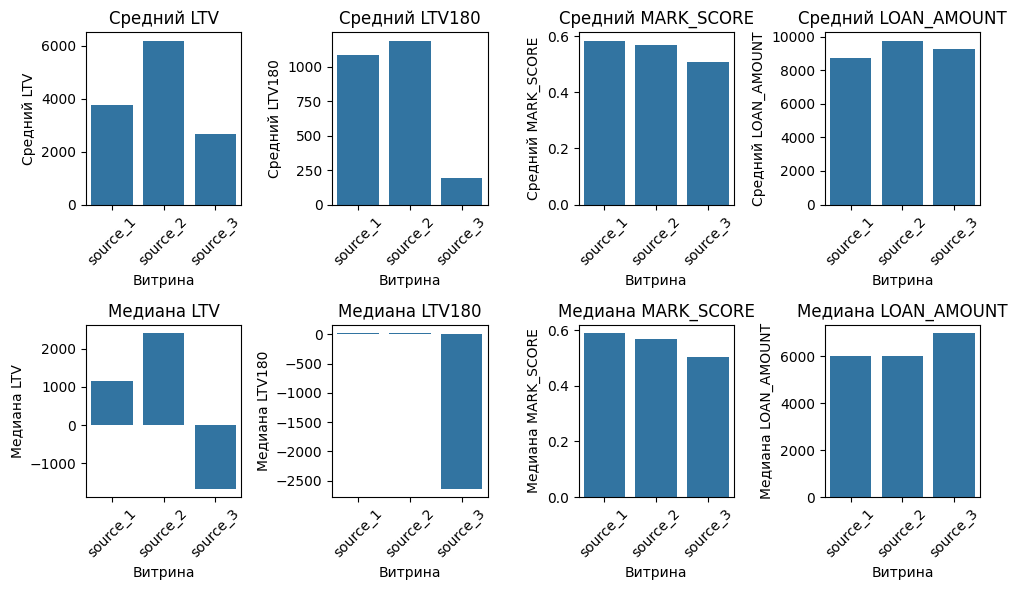

In [1563]:
metrics = ['avg_ltv', 'avg_ltv_180', 'avg_mark', 'avg_loan','med_ltv','med_ltv_180','med_mark','med_loan']
titles = ['Средний LTV', 'Средний LTV180', 'Средний MARK_SCORE', 'Средний LOAN_AMOUNT',
          'Медиана LTV', 'Медиана LTV180', 'Медиана MARK_SCORE', 'Медиана LOAN_AMOUNT']

fig, axes = plt.subplots(2, 4, figsize=(10, 6))
axes = axes.flatten()

for i, (metric, title) in enumerate(zip(metrics, titles)):
    sns.barplot(
        data=df_plot_src,
        x='SOURCE',
        y=metric,        
        ax=axes[i]
    )
    axes[i].set_title(title)
    axes[i].set_xlabel('Витрина')
    axes[i].set_ylabel(title)
    axes[i].tick_params(axis='x', rotation=45)
    #axes[i].legend(title='SOURCE')

plt.tight_layout()
plt.show()

Средние значения показывают радужную картину, а вот медианы возвращают на землю. 
Видно, что витрина source_3 приводит клиентов, которые генерируют убытки. Это при том, что MARK_SCORE немного ниже, чем у клиентов с других витрин, а размер займа на уровне других витрин.


In [1564]:
# создаем дф для визуализации по местам
df_plot_rnk = df_1.groupby('RANK').agg(
    avg_ltv=('LTV','mean'),
    avg_ltv_180=('LTV180','mean'),
    avg_mark=('MARK_SCORE','mean'),
    avg_loan=('LOAN_AMOUNT','mean'),
    med_ltv=('LTV','median'),
    med_ltv_180=('LTV180','median'),
    med_mark=('MARK_SCORE','median'),
    med_loan=('LOAN_AMOUNT','median')
).reset_index()

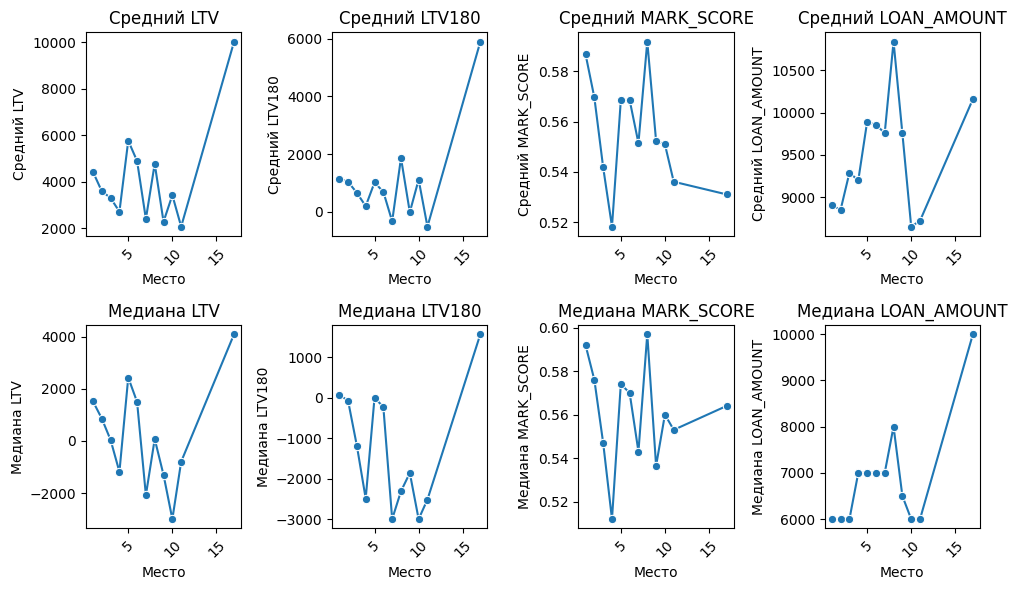

In [1565]:
metrics = ['avg_ltv', 'avg_ltv_180', 'avg_mark', 'avg_loan','med_ltv','med_ltv_180','med_mark','med_loan']
titles = ['Средний LTV', 'Средний LTV180', 'Средний MARK_SCORE', 'Средний LOAN_AMOUNT',
         'Медиана LTV', 'Медиана LTV180', 'Медиана MARK_SCORE', 'Медиана LOAN_AMOUNT']

fig, axes = plt.subplots(2, 4, figsize=(10, 6))
axes = axes.flatten()

for i, (metric, title) in enumerate(zip(metrics, titles)):
    sns.lineplot(
        data=df_plot_rnk,
        x='RANK',
        y=metric,
        #hue='RANK',
        marker='o',
        ax=axes[i]
    )
    axes[i].set_title(title)
    axes[i].set_xlabel('Место')
    axes[i].set_ylabel(title)
    axes[i].tick_params(axis='x', rotation=45)
    #axes[i].legend(title='SOURCE')

plt.tight_layout()
plt.show()

Если смотреть показатели в целом по местам на витринах, без разделения на витрины, то для LTV и LTV180 наблюдается падающий тренд с ростом места. Но медиана вскрыавает более важный момент - отрицательный показатель. То есть, на более низких позициях в сервис приходят клиенты, которые плохо возвращают займы, хотя MARK_SCORE не показывает зависимости от места. Выброс на 17 месте можно не брать в расчет, так как для этого места мало значений для расчета, и любой крупный займ потянет показатель вверх. 
MARK_SCORE и LOAN_AMOUNT изменяются довольно хаотично, и сложно сказать, насколько они зависит от места. Скорее всего, здесь нет явной корреляции. Плюс нужно смотреть на объем информации для каждого места.

Также не лишним будет посмотреть изменения во времени. Хотя бы укрупненно по месяцам в разрезе источников.

In [1566]:
df_plot_dt_src = df_1.groupby(['SAVE_STAMP_MON','SOURCE']).agg(
    avg_ltv=('LTV','mean'),
    avg_ltv_180=('LTV180','mean'),
    avg_mark=('MARK_SCORE','mean'),
    avg_loan=('LOAN_AMOUNT','mean'),
    med_ltv=('LTV','median'),
    med_ltv_180=('LTV180','median'),
    med_mark=('MARK_SCORE','median'),
    med_loan=('LOAN_AMOUNT','median')
).reset_index()

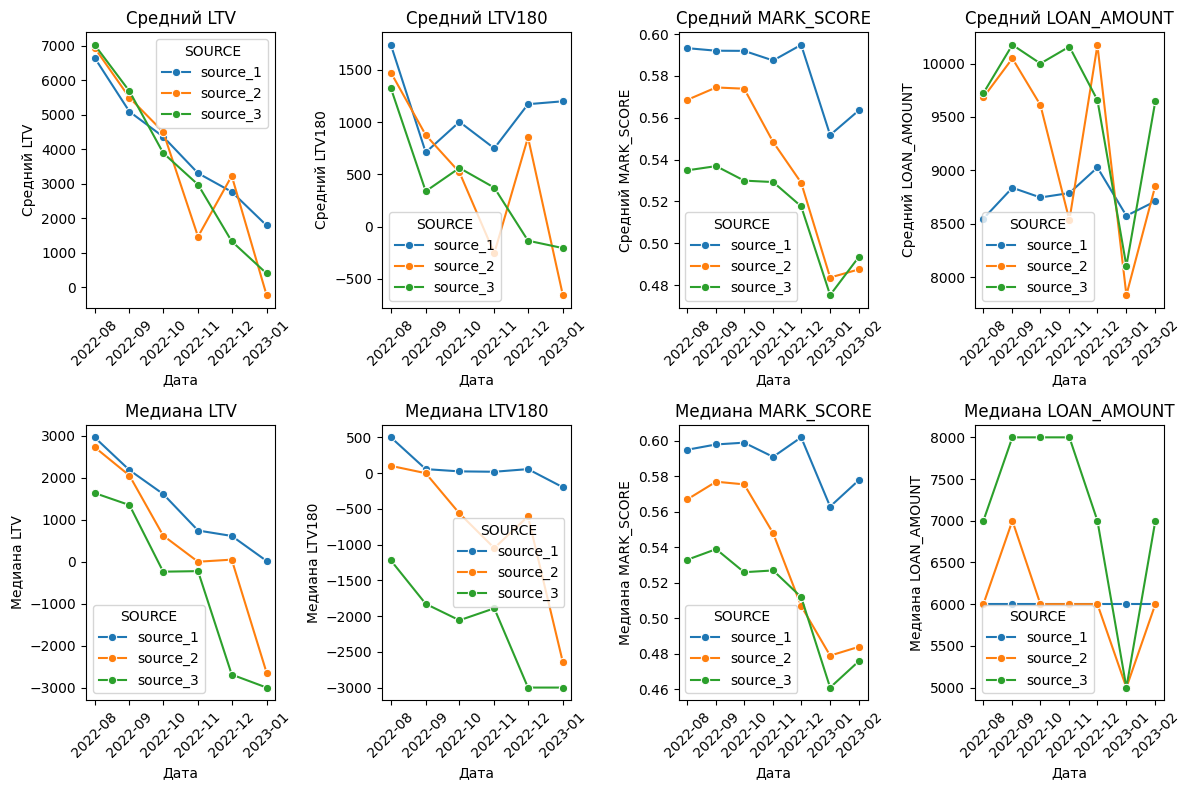

In [1567]:
metrics = ['avg_ltv', 'avg_ltv_180', 'avg_mark', 'avg_loan','med_ltv','med_ltv_180','med_mark','med_loan']
titles = ['Средний LTV', 'Средний LTV180', 'Средний MARK_SCORE', 'Средний LOAN_AMOUNT',
          'Медиана LTV', 'Медиана LTV180', 'Медиана MARK_SCORE', 'Медиана LOAN_AMOUNT']


fig, axes = plt.subplots(2, 4, figsize=(12, 8))
axes = axes.flatten()

for i, (metric, title) in enumerate(zip(metrics, titles)):
    sns.lineplot(
        data=df_plot_dt_src,
        x='SAVE_STAMP_MON',
        y=metric,
        hue='SOURCE',
        marker='o',
        ax=axes[i]
    )
    axes[i].set_title(title)
    axes[i].set_xlabel('Дата')
    axes[i].set_ylabel(title)
    axes[i].tick_params(axis='x', rotation=45)
    axes[i].legend(title='SOURCE')

plt.tight_layout()
plt.show()

Динамика во времени показывает, что LTV у всех витрин имеет падающий характер. Более того витрины 2 и 3 уходят в минус, т.е. приводят убыточных клиентов. Вместе с этим, LTV180 у первой витрины показывает стабильное поведение. Также эта витрина показывает стабильность в суммах займа. Остальные витрины показывают худшие показатели - у них сильно снижается со временем MARK_SCORE, а также снижается сумма займа (особенно, витрина 3). Впрочем, это логично, чем ниже скор клиента, тем меньшую сумму ему одобрят.

#### Вывод
Витрина source_1 демонстрирует, в совокупности, наилучшие исследованные показатели. Также она лучше себя ведет на временном отрезке в полгода.
Зависимость от места на витрине (по витринам в целом) демонстрирует сильные колебания показателей, но заметен тренд, что с ухудшением позиции могут приходить менее прибыльные клиенты.

### Определить средний чек COST для места внутри витрины на этом периоде

Построим средний чек от места, а также средний MARK_SCORE.

In [1568]:
df_cost = df_1.groupby(['SOURCE','RANK'])['COST'].mean().reset_index()


In [1569]:
# посмотрим на количество клиентов по источникам и местам
df_1.groupby(['SOURCE','RANK'])['CLIENT'].count()

SOURCE    RANK
source_1  1.0     39518
          2.0     19980
          3.0      3740
          5.0       399
source_2  1.0      8690
          2.0      1802
          3.0       181
          4.0      2464
          5.0      2111
          6.0      2181
          7.0        29
          8.0         5
          9.0        35
source_3  1.0       736
          2.0       940
          3.0      3711
          4.0      5972
          5.0       321
          6.0       162
          7.0       266
          8.0       166
          9.0       125
          10.0      109
          11.0       68
          17.0       37
Name: CLIENT, dtype: int64

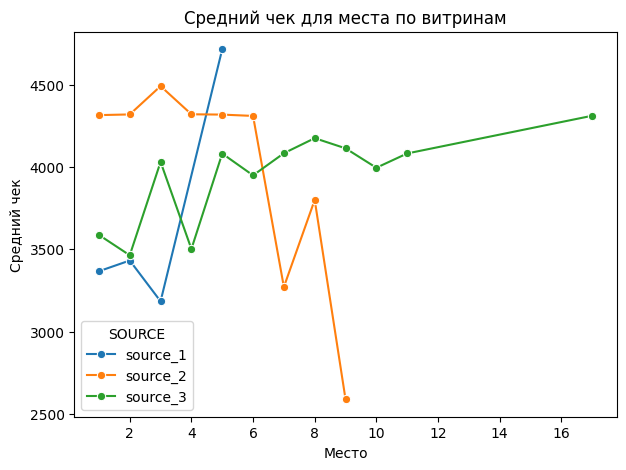

In [1570]:
fig, ax = plt.subplots(figsize=(7, 5))
sns.lineplot(
        data=df_cost,
        x='RANK',
        y='COST',
        hue='SOURCE',
        marker='o'
    )
ax.set_title('Средний чек для места по витринам')
ax.set_xlabel('Место')
ax.set_ylabel('Средний чек')

plt.show()

In [1571]:
df_cost_mark = df_1.groupby(['SOURCE','RANK'])['MARK_SCORE'].mean().reset_index()

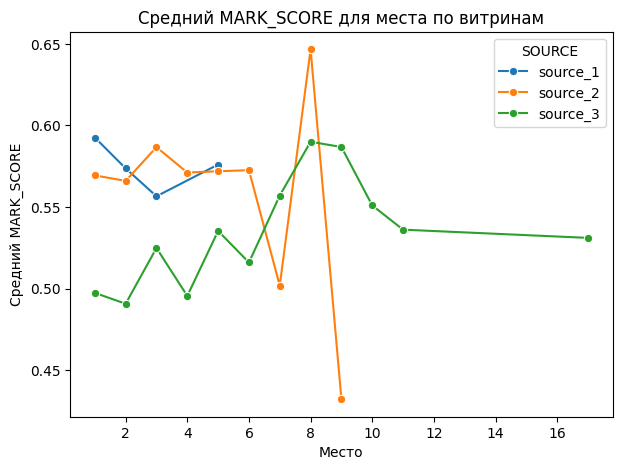

In [1572]:
fig, ax = plt.subplots(figsize=(7, 5))
sns.lineplot(
        data=df_cost_mark,
        x='RANK',
        y='MARK_SCORE',
        hue='SOURCE',
        marker='o'
    )
ax.set_title('Средний MARK_SCORE для места по витринам')
ax.set_xlabel('Место')
ax.set_ylabel('Средний MARK_SCORE')

plt.show()

#### Вывод   
Средний чек, в целом коррелирует с MARK_SCORE, так и должно быть, так как `сколько заплатили витрине за привлечение, зависит от MARK_SCORE`. Но вот для 5 места для source_1 средний чек сильно возрастает, несмотря на не самое большое значение MARK_SCORE. Вероятно, причина в относительно небольшом числе клиентов, пришедших при размещении на этом месте.
На витрина source_1 сервис размещается на 1-5 местах, при этом средний чек, в целом, такой же как и у других витрин (витрина более успешная по сравнению с другими). Оставшиеся витрины размещали на более дальних местах, но чек от этого ниже не становился. вероятно, за счет привлечения клиентов с достаточно высоким MARK_SCORE.

### Влияет ли период выгрузки на занимаемое место и средний чек

In [1573]:
df_cost_rank=df_1.groupby(['SAVE_STAMP_MON','SOURCE']).agg(
    avg_cost=('COST','mean'), 
    rank_min=('RANK','min'),
    rank_max=('RANK','max'),
    avg_rank=('RANK','mean')).reset_index()

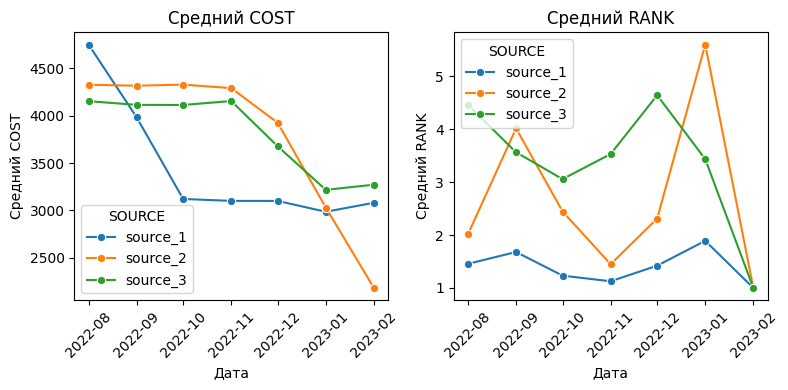

In [1574]:
metrics = ['avg_cost', 'avg_rank']
titles = ['Средний COST', 'Средний RANK']

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes = axes.flatten()

for i, (metric, title) in enumerate(zip(metrics, titles)):
    sns.lineplot(
        data=df_cost_rank,
        x='SAVE_STAMP_MON',
        y=metric,
        hue='SOURCE',
        marker='o',
        ax=axes[i]
    )
    axes[i].set_title(title)
    axes[i].set_xlabel('Дата')
    axes[i].set_ylabel(title)
    axes[i].tick_params(axis='x', rotation=45)
    axes[i].legend(title='SOURCE')

plt.tight_layout()
plt.show()

#### Вывод   
В зависимости от периода выгрузки видно, что в среднем средний чек ниже у source_1, при этом сервис занимает первые места при сравнительно небольшом среднем чеке. А для оставшихся витрин несмотря на достаточно большую величину среднего чека, места хуже, чем для первой витрины.

### Затраты на маркетинг

Для оценки окупаемости маркетинга посчитаем ROMI и ROMI180 по суммарным LTV и COST:

ROMI = (LTV(180) - COST) / COST

In [1575]:
# общие затраты на маркетинг за выбранный период
print(f"Общие затраты на маркетинг за выбранный период {df_1['COST'].sum():,.2f} руб.")
print(f"Общий LTV от клиентов за выбранный период {df_1['LTV'].sum():,.2f} руб.")
print(f"Общий LTV180 от клиентов за выбранный период {df_1['LTV180'].sum():,.2f} руб.")

Общие затраты на маркетинг за выбранный период 316,152,100.00 руб.
Общий LTV от клиентов за выбранный период 356,861,898.34 руб.
Общий LTV180 от клиентов за выбранный период 86,052,686.18 руб.


In [1576]:
all_cost = df_1['COST'].sum()
all_ltv = df_1['LTV'].sum()
all_ltv180 = df_1['LTV180'].sum()

print(f'Общий ROMI {(all_ltv-all_cost)/all_cost*100}')
print(f'Общий ROMI180 {(all_ltv180-all_cost)/all_cost*100}')

Общий ROMI 12.876649668259905
Общий ROMI180 -72.78123846824226


#### Вывод    
Если смотреть на всем диапазоне, то имеется положительный возврат на маркетинговые вложения. А вот в коротком промежутке 180 дней, вложения не окупаются. Это может означать, что в моменте платим за привлечение больше, чем получаем с клиента. Вероятно, что есть в промежутке времени довольно большая сумма невозвратных займов.

###  Связь MARK_SCORE с LTV

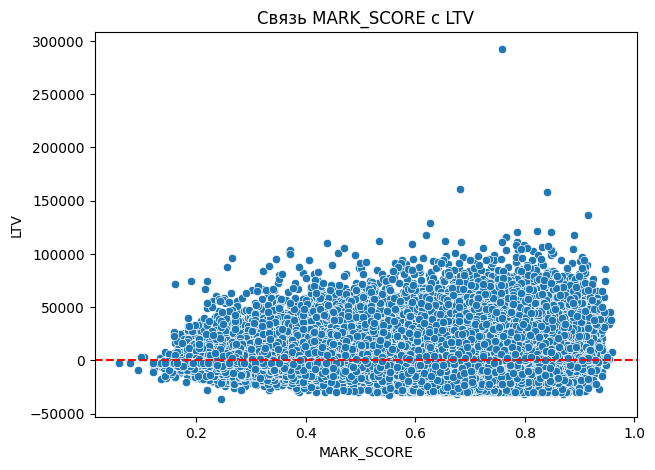

In [1577]:
# общая связь MARK_SCORE с LTV - строим диаграмму рассеяния
fig, ax = plt.subplots(figsize=(7, 5))
sns.scatterplot(data=df_1, x='MARK_SCORE', y='LTV')
ax.axhline(0, color='red', linestyle='--')
ax.set_title('Связь MARK_SCORE с LTV')
plt.show()

На диаграмме видим, что с ростом скора растет и LTV, что вполне логично, так как наиболее надежные заемщики имеют более высокий балл, и своевременно возвращают займы. При этом, практически независимо от скора, есть двольно много заемщиков с отрицательным LTV. То есть, имеется проблема в оценке прибыльности клиента. Он может иметь высокую оценку, но это не гарантирует, что он все вернет и в полном объеме.

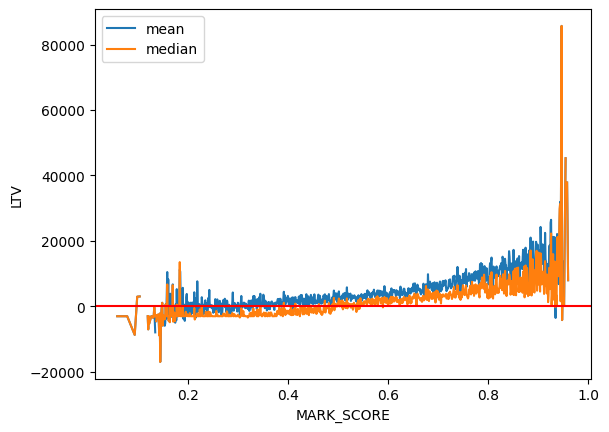

In [1578]:
# построим по всем данным зависимость LTV (среднее и медиана) от MARK_SCORE
df_1.groupby('MARK_SCORE')['LTV'].agg(['mean', 'median']).plot()
plt.ylabel('LTV')
plt.axhline(0, color='red')
plt.show()

В целом, можно предположить, что кривую медианного LTV от MARK_SCORE описывает линейная зависимость, но видно, что кривая состоит из двух частей: примерно до 0,5 - почти горизонтальный характер, и после 0,5 - растущий линейный.  
Разложим график на две части, а также отфильтруем значения больше 20000.

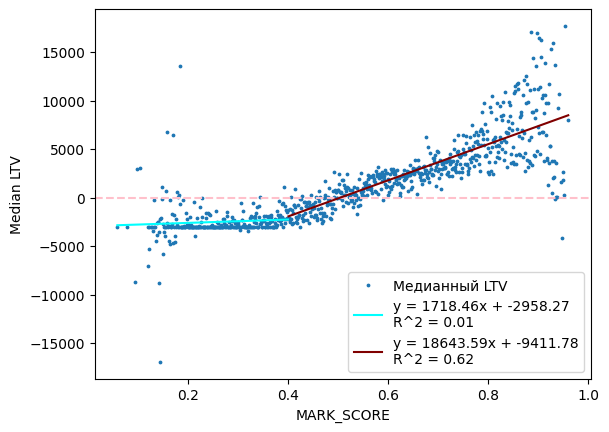

In [1579]:
# аппроксимируем линейной зависимостью медианное LTV от MARK_SCORE
df_plot = df_1.groupby('MARK_SCORE')['LTV'].median().reset_index()
df_plot = df_plot[df_plot['LTV']<=20000]

x = df_plot['MARK_SCORE']
y = df_plot['LTV']

x_1 = df_plot[df_plot['MARK_SCORE']<=0.4]['MARK_SCORE']
y_1 = df_plot[df_plot['MARK_SCORE']<=0.4]['LTV']

x_2 = df_plot[df_plot['MARK_SCORE']>0.4]['MARK_SCORE']
y_2 = df_plot[df_plot['MARK_SCORE']>0.4]['LTV']

result_1 = stats.linregress(x_1, y_1)
result_2 = stats.linregress(x_2, y_2)

k_1 = result_1.slope
b_1 = result_1.intercept
r2_1 = result_1.rvalue**2

k_2 = result_2.slope
b_2 = result_2.intercept
r2_2 = result_2.rvalue**2

plt.scatter(x, y, label='Медианный LTV', s=3)
plt.xlabel('MARK_SCORE')
plt.ylabel('Median LTV')
plt.axhline(0, color='pink', linestyle='--')
plt.plot(x_1, k_1*x_1 + b_1, color='cyan', label=f'y = {k_1:.2f}x + {b_1:.2f}\nR^2 = {r2_1:.2f}')
plt.plot(x_2, k_2*x_2 + b_2, color='maroon', label=f'y = {k_2:.2f}x + {b_2:.2f}\nR^2 = {r2_2:.2f}')
plt.legend()
plt.show()

Получаем две составляющие зависимости и два коэффициента k, которые будут определять величину LTV, в зависимости от значения MARK_SCORE

Также, для общего представления, посмотрим на зависимость LTV (среднее и медиана) от MARK_SCORE в разрезе витрин и мест.

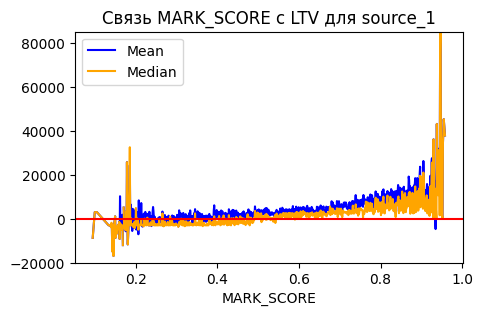

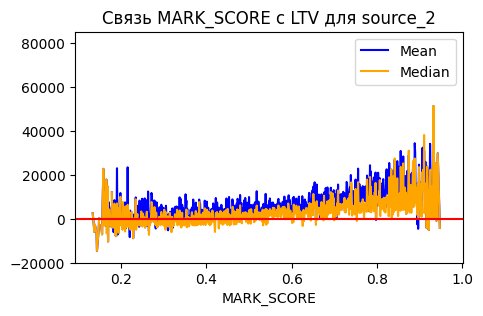

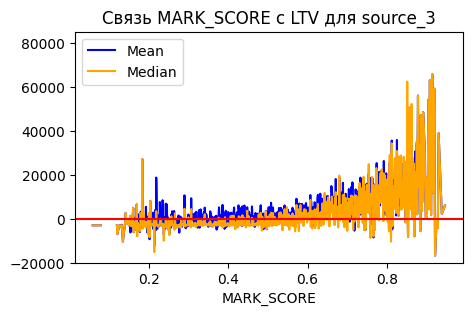

In [1580]:
for src in df_1['SOURCE'].unique():
    # df_plot=df_1[df_1['SOURCE']==src].groupby('MARK_SCORE')['LTV'].mean().reset_index()
    
    fig, ax = plt.subplots(figsize=(5, 3))
    
    df_1[df_1['SOURCE']==src].groupby('MARK_SCORE')['LTV'].mean().plot(ax=ax, label='Mean', color='blue')
    df_1[df_1['SOURCE']==src].groupby('MARK_SCORE')['LTV'].median().plot(ax=ax, label='Median', color='orange')
    # sns.lineplot(data=df_plot, x='MARK_SCORE', y='LTV')
    ax.axhline(0, color='red')    
    ax.set_title(f'Связь MARK_SCORE с LTV для {src}')
    ax.legend()
    plt.ylim(-20000,85000)
    
    plt.show()

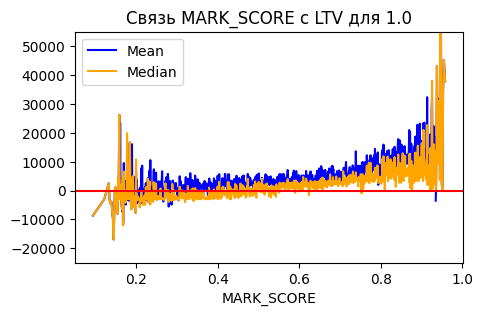

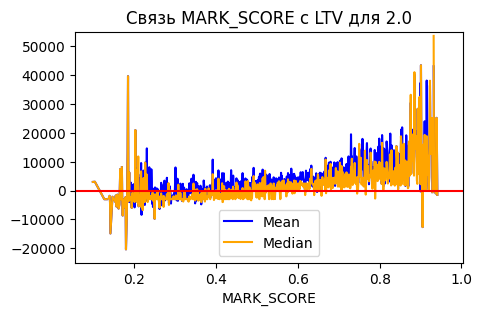

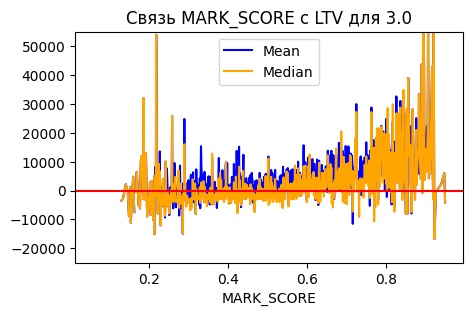

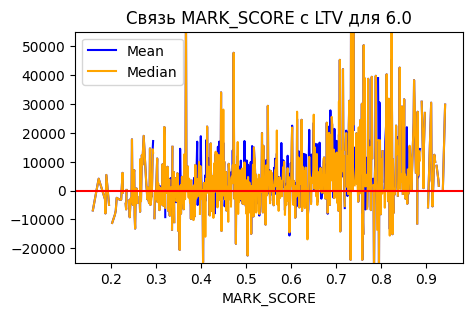

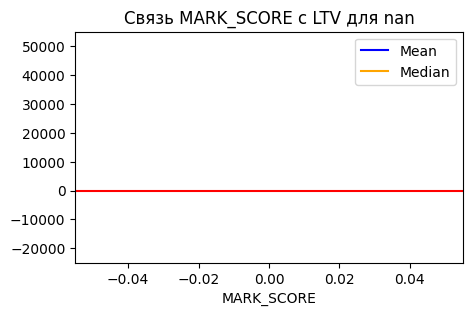

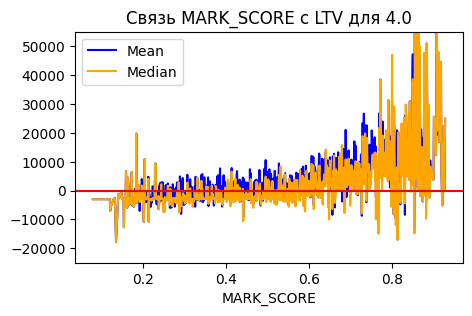

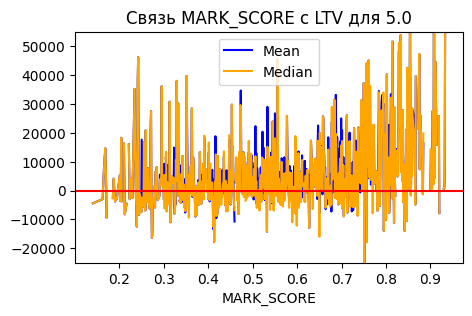

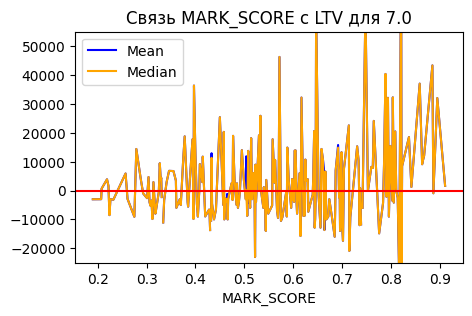

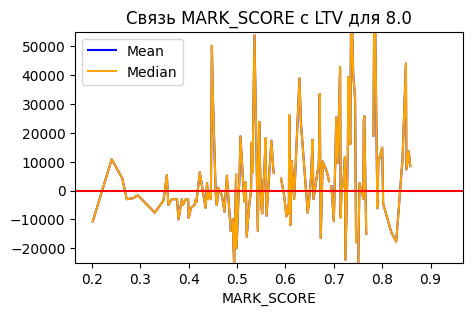

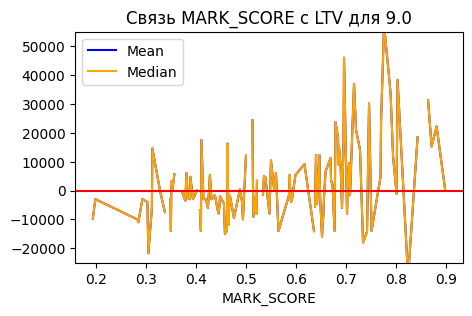

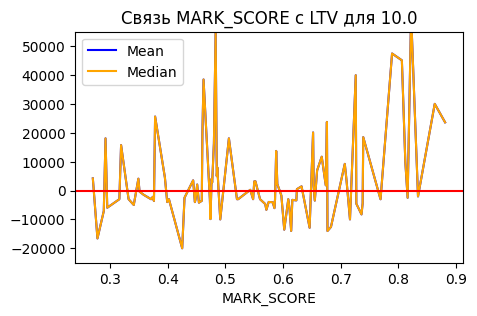

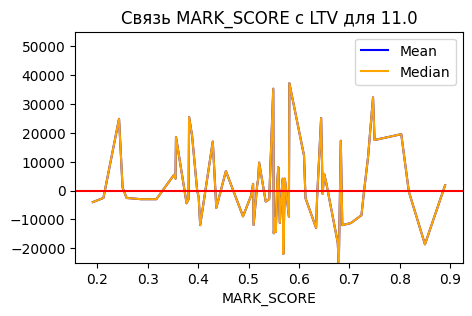

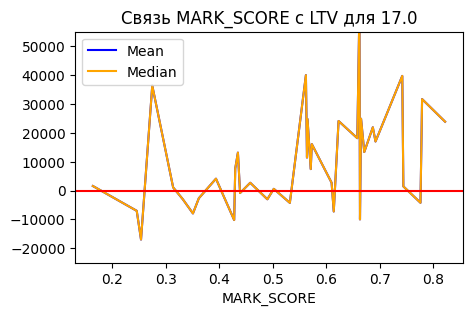

In [1581]:
for rnk in sorted(df_1['RANK'].unique()):
    # df_plot=df_1[df_1['RANK']==rnk].groupby('MARK_SCORE')['LTV'].mean().reset_index()
   
    fig, ax = plt.subplots(figsize=(5, 3))
    df_1[df_1['RANK']==rnk].groupby('MARK_SCORE')['LTV'].mean().plot(ax=ax, label='Mean', color='blue')
    df_1[df_1['RANK']==rnk].groupby('MARK_SCORE')['LTV'].median().plot(ax=ax, label='Median', color='orange')
    # sns.lineplot(data=df_plot, x='MARK_SCORE', y='LTV')
    ax.axhline(0, color='red')    
    ax.set_title(f'Связь MARK_SCORE с LTV для {rnk}')
    ax.legend()
    plt.ylim(-25000,55000)
    plt.show()

#### Вывод  
1. во взаимосвязи LTV и MARK_SCORE наблюдается зависимость, близкая к растущей линейной. Стоит смотреть на медиану LTV, а не на среднее значение, так как среднее в виду смещения распределения дает несколько завышенное значение.
2. можно четко выделить значения MARK_SCORE, при которых LTV меньше нуля, это диапазон от 0,1 до 0,5. больше 0,5 LTV  выше нуля, но чем оно больше, тем шумнее LTV. Т.е. клиент с высоким скором может занимать разово, а может быть постоянным клиентом, регулярно приносящим доход.
3. по витринам видно, что LTV на второй и третьей гораздо шумнее, чем на первой. Т.е. приходят клиенты, которые приносят очень разную прибыль в долгосроке.
4. по месту на витрине видно, что чем ниже позиция, тем шумнее LTV. Вплоть до потери растущего характера.   
В общем, можно сказать, что первая витрина приносит наиболее предсказуемых клиентов по значению LTV, равно как и первые места на витринах. А в целом, имеет место  зависимость между LTV и MARK_SCORE, которую можно аппроксимировать линейной зависимостью y=kx+b, из которой можно вывести коэффициент k и коэффициент детерминации R^2, которые позволят предсказывать с определенной долей уверенности LTV в зависимости от величины MARK_SCORE для каждой витрины и места на ней.
5. произведена аппроксимация линейной зависимостью  LTV от MARK_SCORE. Установлено, что кривая состоит из двух частей, каждая из которых описывается своим уравнением.

## 2. Оценка соответствия насколько поток за рассматриваемый день соответствует витрине/месту

In [1582]:
# формируем датафрейм с данными второго полугодия
df_2 = df[df['SAVE_STAMP_DATE'].between('2023-02-01','2023-08-01')]

Будем исходить из следующей логики:    
чем выше MARK_SCORE, тем больше LTV, чем больше LTV, тем более прибыльный/качественный клиент приходит в сервис.
с другой стороны, чем выше MARK_SCORE, тем больше нужно заплатить витрине, так как согласно вводной информации `COST - сколько заплатили витрине за привлечение, зависит от MARK_SCORE`, а уже в свою очередь, от уплаченной суммы зависит место на витрине.
при этом, чем выше место, тем больший траффик стоит ожидать.   
таким образом, для конкретного дня или промежутка времени, мы должны иметь возможность соотнести следующие показатели:   
- прибыльность клиента (LTV), определяемая из MARK_SCORE, по выведенным ранее коэффициентам
- стоимость привлечения (COST)
- поток клиентов (N)
- витрина (SOURCE)
- место (RANK)

в идеальном раскладе, с ростом стоимости привлечения витрина должна выходить на первые позиции, которые будут приводить достаточно много качественных клиентов.

In [1583]:
def flow_rank(df:pd.DataFrame, first_date:str, n:int, source:str)-> (str,pd.DataFrame):
    '''
    ф-я для определения соответствия места, привлеченному потоку
    принимает на вход:
    df: датафрейм с данными,
    start_date: дата, на котрую хотим посмотреть показатели, 
    n: продолжительность предварительного периода,
    source: название витрины
    внтури ф-ии производится расчет средних показателей за предварительный период, и соотносится с показателями дня,следюущего за предварительным периодом
    если указанный день выходит за пределы датафрейма, то будет выведена информация за предыдущий дате период
    '''
    
    period = n 
    end_date = pd.to_datetime(first_date) - rd.relativedelta(days=1)
    start_date = pd.to_datetime(end_date) - rd.relativedelta(days=n)
   
    if end_date < df['SAVE_STAMP_DATE'].min() or df['SAVE_STAMP_DATE'].max()+rd.relativedelta(days=1) < pd.to_datetime(first_date):
        print('Выбрана некорректная дата. Укажите дату first_date - n дней >= 01-02-2023 или  first_date не больше максимальной даты в датафрейме')
        return None, None
           
    # определяем в конкретный период времени для конкретной витрины средние величины COST, MARK_SCORE, RANK и предсказанный LTV
    exp_df = df[(df['SAVE_STAMP_DATE'].between(pd.to_datetime(start_date),end_date)) & (df['SOURCE']==source)]
   
    exp_avg_cost = round(exp_df['COST'].mean())
    exp_avg_ms = round(exp_df['MARK_SCORE'].mean(),2)
    exp_avg_rnk = round(exp_df['RANK'].mean(),1)
    exp_avg_traf = round(exp_df['CLIENT'].count()/n,0)
    if exp_avg_ms <= 0.4:
        exp_avg_ltv = round(exp_avg_ms*k_1+b_1)
    else:
        exp_avg_ltv = round(exp_avg_ms*k_2+b_2)
    exp = [exp_avg_cost,exp_avg_ms,exp_avg_rnk,exp_avg_ltv,exp_avg_traf]
    
    # определяем параметры для конкретного дня
    if df['SAVE_STAMP_DATE'].max() > pd.to_datetime(first_date):        
        current_df = df[(df['SAVE_STAMP_DATE']==first_date) & (df['SOURCE']==source)]
        avg_cost = round(current_df['COST'].mean())
        avg_ms = round(current_df['MARK_SCORE'].mean(),2)
        avg_rnk = round(current_df['RANK'].mean(),2)
        avg_traf = round(current_df['CLIENT'].count())
        if avg_ms <= 0.4:
            avg_ltv = round(avg_ms*k_1+b_1,2)
        else:
            avg_ltv = round(avg_ms*k_2+b_2,2)
    
        
        current = [avg_cost,avg_ms,avg_rnk,avg_ltv,avg_traf]
        
        exp_date = str(start_date.date())+'_'+str(end_date.date())
        current_date = first_date
        
        result_df = pd.DataFrame({exp_date:exp, current_date:current}, index=['COST','MARK_SCORE','RANK','pred_LTV','Traffic'])
        result_df['diff'] = result_df.iloc[:,1] - result_df.iloc[:,0]
    else:
        exp_date = str(start_date.date())+'_'+str(end_date.date())
        result_df = pd.DataFrame({exp_date:exp}, index=['COST','MARK_SCORE','RANK','pred_LTV','Traffic'])
    return source, result_df   
    

**Примеры использования**

In [1584]:
name, param = flow_rank(df_2, '2023-06-23',6,'source_1')
print(f'Данные по витрине: {name}')
display(param)

Данные по витрине: source_1


,2023-06-16_2023-06-22,2023-06-23,diff
COST,3190.00,3295.00,105.00
MARK_SCORE,0.51,0.51,0.00
RANK,1.70,1.50,-0.20
pred_LTV,96.00,96.45,0.45
Traffic,863.00,768.00,-95.00


На конкретную дату 2023-06-23 смотрим показатели. Видим, что конкретный день почти не отличается от предыдущей недели. Есть небольшое снижение по трафику, место колеблется от 1 до 2, предсказывается небольшой LTV, но он положителен. Можно оставаться на этой витрине, не меняя места.

In [1585]:
name, param = flow_rank(df_2, '2023-06-23',6,'source_3')
print(f'Данные по витрине: {name}')
display(param)

Данные по витрине: source_3


,2023-06-16_2023-06-22,2023-06-23,diff
COST,3015.00,3062.00,47.0
MARK_SCORE,0.44,0.44,0.0
RANK,2.00,2.00,0.0
pred_LTV,-1209.00,-1208.60,0.4
Traffic,173.00,133.00,-40.0


Третья витрина на той же дате, что и первая. Видим что при сопоставимых расходах на маркетинг, клиенты имеют чуть меньший скор, место на витрине стабильное второе, но при этом трафик гораздо ниже, чем на первой, а предсказываемый LTV отрицательный и довольно большой. Данная витирина менее эффективна, имеет смысл снизить на ней расходы на маркетинг и снизить место до 3-5. Возможно, что на время можно отказаться от данной витрины.

In [1586]:
name, param = flow_rank(df_2, '2023-08-01',6,'source_1')
print(f'Данные по витрине: {name}')
display(param)

Данные по витрине: source_1


,2023-07-25_2023-07-31
COST,2951.00
MARK_SCORE,0.51
RANK,1.00
pred_LTV,96.00
Traffic,384.00


In [1587]:
name, param = flow_rank(df_2, '2023-08-01',6,'source_3')
print(f'Данные по витрине: {name}')
display(param)

Данные по витрине: source_3


,2023-07-25_2023-07-31
COST,3204.00
MARK_SCORE,0.48
RANK,3.00
pred_LTV,-463.00
Traffic,204.00


Аналогично выводим две витрины, но на основании данных за прошлую неделю делаем прогноз о месте на следующий день.  
По первой витрине сохраняем место. При сравнимых расходах на маркетинг она дает больше более качественного трафика с положительным LTV. Третья витрина, при чуть больших расходах, размещает только на третьем месте, а предполагаемый LTV имеет отрицательный характер. Стоит снизить маркетинговые расходы и снизить место на данной витрине.